# 🎓 Predicting Student Mental Health Score from Social Media Usage

**Problem Statement:**

Predict a student's `Mental_Health_Score` (a continuous numerical value ranging approximately from 3 to 10) using social media habits, study time, sleep duration, physical activity, and stress level.

**Problem Type:** Regression, because the target variable is a continuous numerical value.

**Dataset:** `Student_Social_Media_And_Mental_Health_Impact.csv`

**Dataset Information:**

* Total Rows: 5,000 students
* Total Columns: 13

**Features:**

* **Demographics:** Age, Gender, Country
* **Social Media Usage:** Avg_Daily_Usage_Hours, Daily_Unlocks, Most_Used_Platform
* **Lifestyle:** Study_Hours, Sleep_Hours_Per_Night, Physical_Activity_Hours
* **Stress:** Stress_Level

**Target Variable:** `Mental_Health_Score`


## 1. Import Libraries

In this step, we import the required Python libraries for data handling, data visualization, preprocessing, model training, model evaluation, and saving the trained model.

Grouping imports by purpose keeps the code organized, readable, and easy to understand.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the Dataset

In this step, we load the dataset from a CSV file using Pandas.

We check the shape of the dataset to understand the number of rows and columns, and display the first few rows to get an initial overview of the data.

This step helps us understand the dataset before performing data cleaning, exploratory data analysis (EDA), and preprocessing.


In [2]:
df=pd.read_csv("Student Social Media And Mental Health Impact.csv")

In [3]:
# fast 5 row
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [4]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [5]:
df.shape

(5000, 13)

📌 Reading this: Zero duplicate rows. Nothing to remove here, but we always check — silently keeping duplicate rows can quietly bias a model toward whatever got repeated.

In [6]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(2)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [9]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


📌 Reading this: Most columns look reasonable — but look closely at Physical_Activity_Hours: the minimum value is -0.4. Negative hours aren't physically possible, so this is a data-entry glitch, not a real value. We'll fix this properly in the Data Cleaning step below instead of ignoring it.

## 4. Exploratory Data Analysis (EDA)

In this section, we explore the dataset using six carefully selected visualizations. Each plot helps us understand a specific aspect of the data, identify patterns and relationships, and gain useful insights before moving on to data preprocessing and model training.


### 4.1 — Distribution of the Target (`Mental_Health_Score`)

Before building our model, we first examine the distribution of the target variable, `Mental_Health_Score`. This helps us understand how the scores are spread across the dataset, identify common score ranges, and check for potential skewness or unusual values.


<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

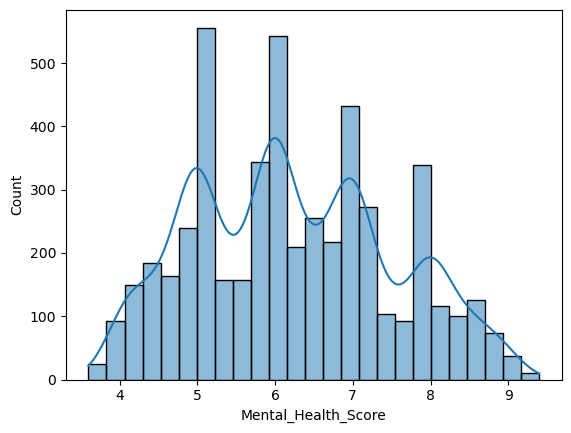

In [10]:
sns.histplot(df['Mental_Health_Score'], kde=True)

### 4.2 — Correlation Heatmap

A correlation heatmap helps us understand the relationships between numerical features in the dataset. It shows the strength and direction of the linear relationship between pairs of variables, helping us identify features that may be associated with the target variable, `Mental_Health_Score`.


In [11]:
df.corr(numeric_only=True)

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
Age,1.000000,-0.070092,-0.074488,0.083109,0.012984,0.088681,0.100785
Avg_Daily_Usage_Hours,-0.070092,1.000000,0.960187,-0.878645,-0.625707,-0.808388,-0.816453
Daily_Unlocks,-0.074488,0.960187,1.000000,-0.853397,-0.602828,-0.781823,-0.790851
Study_Hours,0.083109,-0.878645,-0.853397,1.000000,0.560532,0.730136,0.752626
Physical_Activity_Hours,0.012984,-0.625707,-0.602828,0.560532,1.000000,0.507851,0.521374
Sleep_Hours_Per_Night,0.088681,-0.808388,-0.781823,0.730136,0.507851,1.000000,0.766430
Mental_Health_Score,0.100785,-0.816453,-0.790851,0.752626,0.521374,0.766430,1.000000


<Axes: >

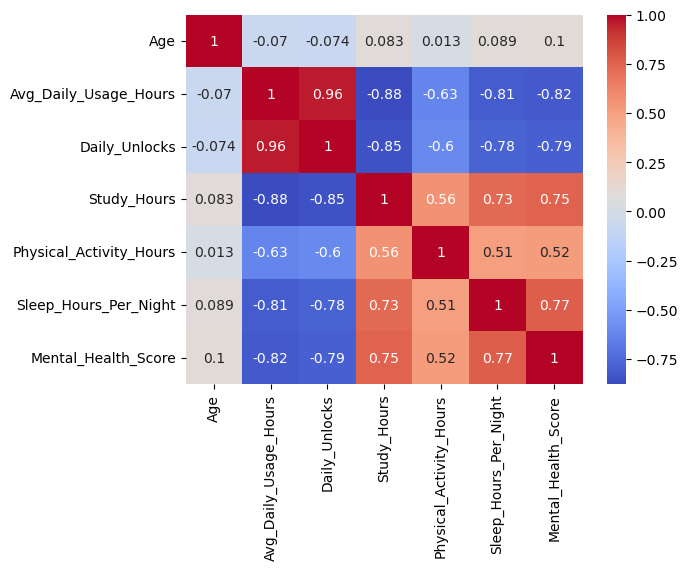

In [12]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

### 4.3 — Stress Level vs Mental Health Score

In this section, we compare stress level with mental health score to understand how they are related. This helps us see whether mental health scores change when stress levels change.

In [13]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [14]:
df["Stress_Level"].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

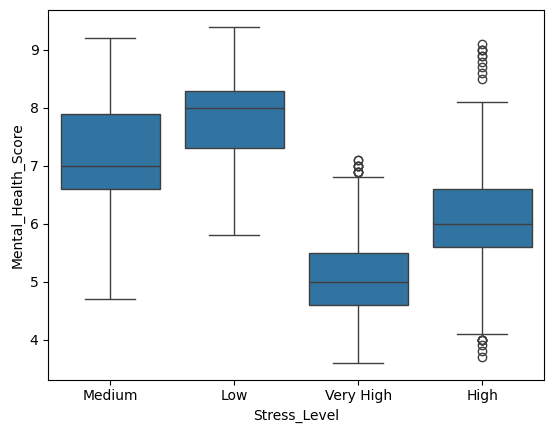

In [15]:
sns.boxplot(x="Stress_Level",y="Mental_Health_Score",data=df)

### 4.4 — Daily Usage Hours vs Mental Health Score

In this section, we compare daily social media usage hours with mental health scores. This helps us understand whether spending more time on social media is related to changes in mental health scores.

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

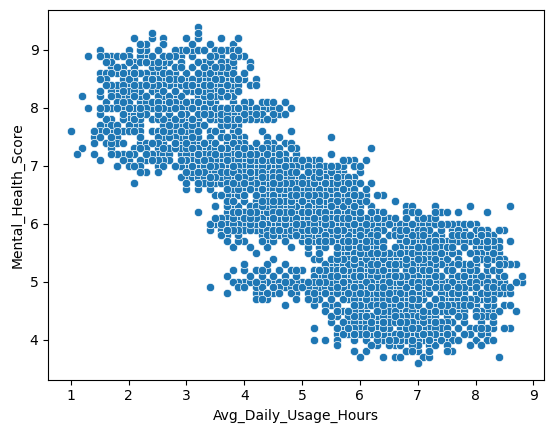

In [16]:
sns.scatterplot(x='Avg_Daily_Usage_Hours', y='Mental_Health_Score',data=df)

### 4.5 — Sleep Hours vs Mental Health Score

In this section, we compare sleep hours with mental health scores to understand how they are related. This helps us see whether getting more or less sleep is associated with changes in mental health scores.

In [17]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

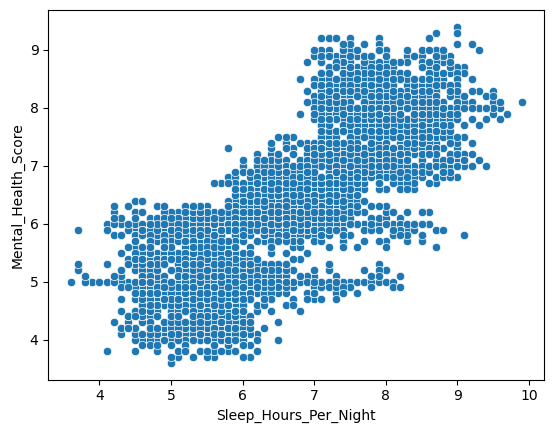

In [18]:
sns.scatterplot(x='Sleep_Hours_Per_Night', y='Mental_Health_Score', data=df)

### 4.6 — Most Used Platform (Count)

In this section, we count how many people use each social media platform. This helps us identify the most and least popular platforms in our dataset.

In [19]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [20]:
df["Most_Used_Platform"].unique()

array(['Facebook', 'LinkedIn', 'Instagram', 'Snapchat', 'Twitter',
       'YouTube', 'TikTok', 'LINE', 'KakaoTalk', 'VKontakte', 'WhatsApp',
       'WeChat'], dtype=object)

<Axes: xlabel='count', ylabel='Most_Used_Platform'>

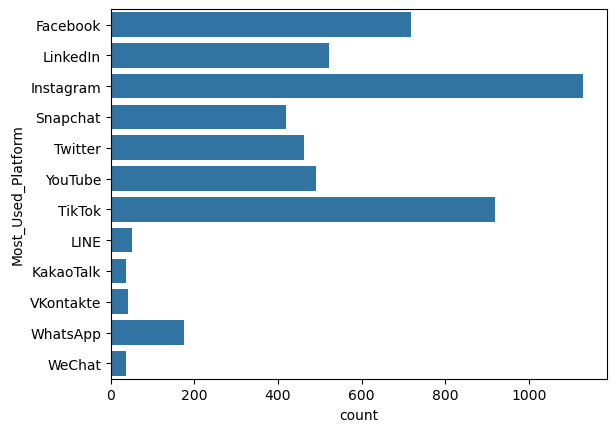

In [21]:
sns.countplot(y="Most_Used_Platform",data=df)

### 4.7 — Checking Outliers

In this section, we check for outliers in the numerical columns. Outliers are values that are much higher or lower than most other values. Identifying them helps us understand the data better and decide whether they need to be handled.

In [22]:
num_features = df.select_dtypes(include='number') #int64 or float64
Q1  = num_features.quantile(0.25)
Q3  = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


## 5. Data Cleaning

In this section, we clean the dataset by handling missing values, removing duplicate rows, and checking for incorrect data. This helps us prepare clean and reliable data for model training.

In [23]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [24]:
df = df.drop_duplicates()

In [25]:
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

📌 **Why use `clip(lower=0)` instead of dropping the row?**

We use `clip(lower=0)` to replace negative values with 0 instead of removing the entire row. The other information in that row may still be useful for our analysis and model training.

We are not dropping any columns because each column may help us predict mental health scores. We also checked that no columns are completely empty or contain only one unique value.

## 6. Skewness

**What is skewness?**

Skewness tells us whether the data is balanced or leans more towards one side. A value near 0 means the data is roughly symmetric, while a positive or negative value means the data has a longer tail on one side.

**Why does it matter?**

Highly skewed data can affect some machine learning models. Since we are using Linear Regression as a baseline model, checking skewness helps us decide whether any numerical features need transformation. Tree-based models like Random Forest are generally less affected by skewness.

In [26]:
num_cols = df.select_dtypes(include='number')
num_cols.skew()
# near to 0 -> Centralized (0.01, 0.002)
# negative -> Left Skewed (-1.56)
# poistive (greater than 0) -> Right Skewed (1.256)

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

## 7. Feature Engineering

In this section, we create a new feature by grouping the `Country` column.

The `Country` column contains 111 unique values. Using one-hot encoding for all these countries would create too many columns.

Dropping the `Country` column completely could also remove useful information.

To solve this, we keep the 10 most frequent countries as separate categories and group all the remaining countries into `"Other"`. This reduces the number of categories while keeping potentially useful information for model training.

In [27]:
df.nunique()

Age                          7
Gender                       2
Country                    111
Academic_Level               3
Most_Used_Platform          12
Purpose_Of_Use               4
Avg_Daily_Usage_Hours       79
Daily_Unlocks              200
Study_Hours                 76
Physical_Activity_Hours     40
Sleep_Hours_Per_Night       63
Stress_Level                 4
Mental_Health_Score         59
dtype: int64

In [28]:
top_countries = df['Country'].value_counts().index[:10].tolist()

In [29]:
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Turkey',
 'Mexico',
 'France']

In [30]:
def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

In [31]:
df['Grouped_country'] = df['Country'].apply(group_countries)

In [32]:
df['Grouped_country'].value_counts()

Grouped_country
Other        3231
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

📌 **Result:** We reduced the number of country categories from 111 to 11 by keeping the top 10 countries and grouping the remaining countries into `"Other"`. This makes the data easier to handle and helps us avoid creating too many columns during one-hot encoding.

In [33]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Grouped_country
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,Other
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6,Other
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0,Canada
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3,Other
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4,Other


## 8. Encoding Strategy

Before training the model, we need to convert categorical data into numerical values.

- **`Stress_Level` → Ordinal Encoding:** Stress levels have a natural order: Low, Medium, High, and Very High. We encode them as 0, 1, 2, and 3 to keep this order.

- **`Gender`, `Academic_Level`, `Most_Used_Platform`, `Purpose_Of_Use`, `Country_Grouped` → One-Hot Encoding:** These columns contain categories without a natural order. One-hot encoding converts them into separate 0/1 columns so the model does not assume that one category is greater than another.

We will use a `ColumnTransformer` to apply both encoding methods in one place. This makes our preprocessing code easier to manage and reuse.

## 9. Train-Test Split

We split the dataset into training and testing sets to check how well the model performs on unseen data.

We use an 80/20 split, where 80% of the data is used for training and 20% is used for testing. For 5,000 rows, this means 4,000 rows for training and 1,000 rows for testing.

We split the data before fitting any preprocessing steps to avoid data leakage. This ensures that information from the test set does not influence the training process.

In [34]:
from sklearn.model_selection import train_test_split

skwewd_col         = ['Study_Hours']
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level']
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Grouped_country"]


feature_col = skwewd_col + other_numeric_cols + ordinal_col + normal_col
X = df[feature_col]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
     

## 10. Preprocessing Using ColumnTransformer

Different columns need different preprocessing steps before training the model.

- **`Study_Hours`:** Fill missing values, apply `log1p` to reduce skewness, and scale the values.
- **Other numerical columns:** Fill missing values and scale the values.
- **`Stress_Level`:** Fill missing values and use `OrdinalEncoder` with a specified order.
- **Other categorical columns:** Fill missing values and apply `OneHotEncoder`.

We use `SimpleImputer` in each pipeline to handle missing values, even though the current dataset has no missing values. This makes the preprocessing pipeline more reliable when working with new data.

Finally, `ColumnTransformer` combines these steps into one object. It applies the correct preprocessing to each group of columns and makes the code easier to manage and reuse.

In [35]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
#1. Skewed features
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())

])

#2. Numeric Features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale',StandardScaler())
])

#3. Ordinal
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))
])

#4. Nominal Features
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])


    # (konsi_pipeline, konsa_feature)
preprocessor = ColumnTransformer(transformers=[
    ("Skewed_Pipeline", skew_pipeline, skwewd_col),
    ("Plain_Numeric",plain_numeric_pipeline, other_numeric_cols ),
    ('Ordinal', ordinal_pipeline, ordinal_col),
    ('Normal', nominal_pipeline, normal_col)
])

In [36]:
preprocessor.fit(X_train)   # or: preprocessor.fit(X_train, y_train)

,transformers,"[('Skewed_Pipeline', ...), ('Plain_Numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,func,<ufunc 'log1p'>
,inverse_func,None
,validate,False


## 11. Build a Pipeline

A `Pipeline` combines preprocessing steps and a machine learning model into one object.

When we call `.fit()`, the pipeline preprocesses the training data and trains the model. When we call `.predict()` on new data, it automatically applies the same preprocessing steps before making predictions.

This helps us avoid repeating preprocessing steps manually and keeps the process consistent.

Pipelines are also useful for deployment. In Part 2, we will use FastAPI to deploy the model. The API can load the saved pipeline and make predictions on new input data without manually applying scaling, encoding, or other transformations.

We will build two separate pipelines, one for each model, so we can compare their performance fairly.

## 12. Model Building

In this section, we train two machine learning models: Linear Regression and Random Forest.

Linear Regression is our baseline model. Random Forest can learn more complex patterns in the data.

By comparing these two models, we can understand which one performs better at predicting mental health scores.

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
lr_preds       = lr_pipeline.predict(X_test)
lr_preds_train = lr_pipeline.predict(X_train)

lr_r2_testing  = r2_score(y_test, lr_preds)
lr_r2_training = r2_score(y_train, lr_preds_train)
lr_mae         = mean_absolute_error(y_test, lr_preds)

print(f"Accuracy of Training {lr_r2_training}")
print(f"Accuracy of Testing {lr_r2_testing}")
print(f'MAE {lr_mae}')

Accuracy of Training 0.7236771199387539
Accuracy of Testing 0.739794461743302
MAE 0.5361775634720183


### 12.2 — Random Forest (Default Settings)

In this section, we train a Random Forest model using its default settings. We use the same preprocessing steps as Linear Regression but replace the model with Random Forest.

This allows us to compare both models fairly and understand which one predicts mental health scores more accurately.

In [38]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('random forest', RandomForestRegressor(random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_preds          = rf_pipeline.predict(X_test)
rf_preds_training = rf_pipeline.predict(X_train)

rf_r2_testing  = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_training)
rf_mae         = mean_absolute_error(y_test, rf_preds)

print(f"Accuracy of Training {rf_r2_training}")
print(f"Accuracy of Testing {rf_r2_testing}")
print(f"MAE : {rf_mae}")

Accuracy of Training 0.9808287942404612
Accuracy of Testing 0.8775888638668996
MAE : 0.34722113333333343


In [39]:
rf_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('random forest', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('Skewed_Pipeline', ...), ('Plain_Numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### 12.3 — Hyperparameter Tuning the Random Forest

In this section, we use `RandomizedSearchCV` to find better settings for the Random Forest model.

Since we are using a Pipeline, we add `regressor__` before each model parameter so that the search knows which step to tune.

We use `RandomizedSearchCV` instead of `GridSearchCV` because it tests a selected number of parameter combinations rather than every possible combination. This saves time while helping us find a model with better performance.

In [40]:


from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'random forest__n_estimators'       : [100,200,300],
    'random forest__max_depth'         : [5,10,15],
    'random forest__min_samples_split' : [2,5,10],
    'random forest__min_samples_leaf'  : [1,2,4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter = 15,
    cv = 5,
    scoring='r2',
    random_state=42,
    n_jobs =-1 #processor free
)

random_search.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'random forest__max_depth': [5, 10, ...], 'random forest__min_samples_leaf': [1, 2, ...], 'random forest__min_samples_split': [2, 5, ...], 'random forest__n_estimators': [100, 200, ...]}"
,n_iter,15
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [41]:
random_search.best_params_

{'random forest__n_estimators': 200,
 'random forest__min_samples_split': 5,
 'random forest__min_samples_leaf': 2,
 'random forest__max_depth': 15}

In [43]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds    = rf_best_pipeline.predict(X_test)
print(f"Accuracy of Testing {r2_score(y_test, rf_best_preds)}")
print(f"MAE : {mean_absolute_error(y_test, rf_best_preds)}")

Accuracy of Testing 0.8650140569761653
MAE : 0.3689015766630922


## 13. Model Evaluation

In this section, we evaluate both models using three metrics: R² Score, MAE, and RMSE.

- **R² Score:** Measures how well the model explains the variation in mental health scores. A score closer to 1 generally indicates a better fit.
- **MAE (Mean Absolute Error):** Measures the average absolute difference between the actual scores and predicted scores. It is easy to understand because the error is measured in score points.
- **RMSE (Root Mean Squared Error):** Measures prediction errors and gives more weight to larger mistakes. A lower RMSE generally indicates better predictions.

During hyperparameter tuning, cross-validation R² helps us compare model performance across different data splits. Finally, we evaluate the selected model on the untouched test set to check how well it performs on unseen data.

In [44]:
from sklearn.metrics import mean_squared_error

# Calculate RMSE for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))

# Calculate RMSE for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

# Calculate RMSE for tuned Random Forest
rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)

In [45]:
# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

                     Model        R2  Training R2       MAE      RMSE
0        Linear Regression  0.739794     0.723677  0.536178  0.676032
1  Random Forest (default)  0.877589     0.980829  0.347221  0.463681
2    Random Forest (tuned)  0.865014     0.954703  0.368902  0.486915


## 14. Save the Model

In this section, we save the entire machine learning pipeline, including preprocessing steps and the trained model, into a single file.

**Why save the entire pipeline?**

If we save only the Random Forest model, we must manually apply the same preprocessing steps, such as encoding and scaling, before making predictions. This can lead to errors if the preprocessing is not done correctly.

By saving the complete pipeline, our FastAPI backend can load one file and call `.predict()` on new input data. The pipeline automatically applies the same preprocessing steps used during training and then generates the prediction.

This makes the model easier to use, deploy, and maintain.

In [46]:
import joblib
joblib.dump(rf_pipeline, 'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']

# Next Steps (Part 2)

In the next part, we will turn our trained machine learning model into a working web application.

1. **Build a FastAPI Backend:** Create a backend that loads `mental_health_pipeline.pkl` and provides a `/predict` endpoint.
2. **Validate Input with Pydantic:** Check that the input data contains the required fields and valid values before making predictions.
3. **Connect a Frontend:** Build a simple user interface where users can enter their details and view the predicted mental health score.
4. **Deploy the Application:** Deploy the backend and frontend so that anyone can access and use the project online.

**Final Goal:** Create a live, interactive Mental Health Score Prediction demo using Machine Learning, FastAPI, and a frontend.

In [47]:
df.columns.tolist()

['Age',
 'Gender',
 'Country',
 'Academic_Level',
 'Most_Used_Platform',
 'Purpose_Of_Use',
 'Avg_Daily_Usage_Hours',
 'Daily_Unlocks',
 'Study_Hours',
 'Physical_Activity_Hours',
 'Sleep_Hours_Per_Night',
 'Stress_Level',
 'Mental_Health_Score',
 'Grouped_country']